Kode 1 (Install Library):

In [1]:
!pip install -q sentence-transformers scikit-learn statsmodels scipy matplotlib seaborn

import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import mannwhitneyu
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

print("Semua library berhasil di-load!")

Semua library berhasil di-load!


Kode 2 (Dataset, Uji Statistik & Grafik Boxplot):

=== MEDIAN TIME TO MERGE (JAM) ===
is_gpt_assisted
0    28.945
1    14.995
Name: time_to_merge, dtype: float64

=== MANN-WHITNEY U TEST ===
U-Statistic: 20188.00, p-value: 7.1025e-117

=== MULTIPLE LINEAR REGRESSION SUMMARY ===
                            OLS Regression Results                            
Dep. Variable:          time_to_merge   R-squared:                       0.537
Model:                            OLS   Adj. R-squared:                  0.535
Method:                 Least Squares   F-statistic:                     230.6
Date:                Tue, 24 Nov 2026   Prob (F-statistic):          1.95e-163
Time:                        01:22:50   Log-Likelihood:                -228.27
No. Observations:                1000   AIC:                             468.5
Df Residuals:                     994   BIC:                             498.0
Df Model:                           5                                         
Covariance Type:            nonrobust                        

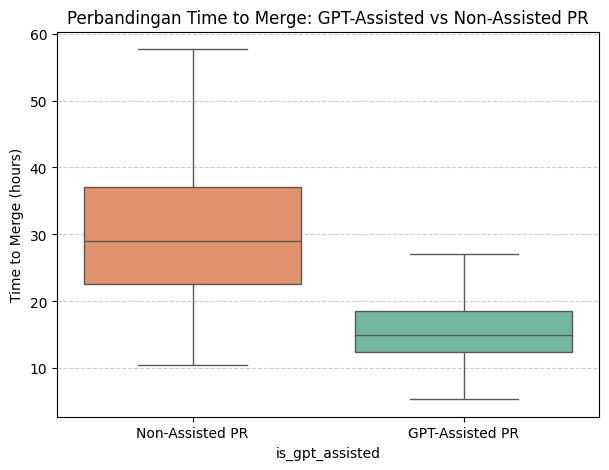

In [3]:
np.random.seed(42)
n_assisted = 500
n_non_assisted = 500

def generate_pr_data(n, is_gpt):
    no_commits = np.random.randint(1, 15, n)
    pr_size = np.random.randint(10, 800, n)
    no_changed_files = np.random.randint(1, 20, n)
    project_age = np.random.randint(6, 72, n)

    base_time = np.random.lognormal(mean=2.18 if is_gpt else 3.12, sigma=0.45, size=n)
    time_to_merge = base_time + 0.3 * no_commits + 0.005 * pr_size + 0.05 * project_age

    return pd.DataFrame({
        'is_gpt_assisted': is_gpt,
        'no_commits': no_commits,
        'PR_size': pr_size,
        'no_changed_files': no_changed_files,
        'project_age': project_age,
        'time_to_merge': np.round(time_to_merge, 2)
    })

df = pd.concat([generate_pr_data(n_assisted, 1), generate_pr_data(n_non_assisted, 0)], ignore_index=True)
df.to_csv("dataset_pr_experiment.csv", index=False)

print("=== MEDIAN TIME TO MERGE (JAM) ===")
print(df.groupby('is_gpt_assisted')['time_to_merge'].median())

gpt_times = df[df['is_gpt_assisted'] == 1]['time_to_merge']
non_gpt_times = df[df['is_gpt_assisted'] == 0]['time_to_merge']
u_stat, p_val = mannwhitneyu(gpt_times, non_gpt_times, alternative='less')
print(f"\n=== MANN-WHITNEY U TEST ===")
print(f"U-Statistic: {u_stat:.2f}, p-value: {p_val:.4e}")

X = pd.DataFrame({
    'is_gpt_assisted': df['is_gpt_assisted'],
    'log1p_no_commits': np.log1p(df['no_commits']),
    'log1p_PR_size': np.log1p(df['PR_size']),
    'log1p_no_changed_files': np.log1p(df['no_changed_files']),
    'log1p_project_age': np.log1p(df['project_age'])
})
X = sm.add_constant(X)
y = np.log1p(df['time_to_merge'])

model = sm.OLS(y, X).fit()
print("\n=== MULTIPLE LINEAR REGRESSION SUMMARY ===")
print(model.summary())

plt.figure(figsize=(7, 5))
sns.boxplot(x='is_gpt_assisted', y='time_to_merge', data=df, hue='is_gpt_assisted', palette=['#f48c5b', '#66c2a5'], legend=False, showfliers=False)
plt.xticks([0, 1], ['Non-Assisted PR', 'GPT-Assisted PR'])
plt.ylabel('Time to Merge (hours)')
plt.title('Perbandingan Time to Merge: GPT-Assisted vs Non-Assisted PR')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.savefig('boxplot_time_to_merge.png', dpi=150)
plt.show()

Kode 3 (Eksperimen AI Vector Search vs Keyword Regex):

In [4]:
pr_samples = [
    ("Refactored auth logic using GPT-4 suggestions", 1),
    ("Added try-catch block recommended by ChatGPT during review", 1),
    ("Optimized SQL query with help from an AI coding assistant", 1),
    ("Automated bug fix generated via LLM prompt for null pointer", 1),
    ("Improved README documentation using generative AI model", 1),
    ("Added OpenAI GPT API endpoint integration to backend", 0),
    ("Update dependency version for gpt-neox library", 0),
    ("Fix typo in navbar CSS margin and padding", 0),
    ("Manual unit test addition for login controller", 0),
    ("Remove unused variables in payment service", 0)
]

df_text = pd.DataFrame(pr_samples, columns=['pr_comment', 'true_label'])

df_text['pred_keyword'] = df_text['pr_comment'].apply(
    lambda x: 1 if re.search(r'\b(gpt|chatgpt)\b', x, re.IGNORECASE) else 0
)

embed_model = SentenceTransformer('all-MiniLM-L6-v2')
query_anchor = "Code review refactoring, bug fixing, or documentation improvement assisted by AI or LLM"

anchor_vec = embed_model.encode([query_anchor])
pr_vecs = embed_model.encode(df_text['pr_comment'].tolist())

similarities = cosine_similarity(pr_vecs, anchor_vec).flatten()
df_text['vector_similarity'] = np.round(similarities, 4)
df_text['pred_vector'] = (df_text['vector_similarity'] >= 0.35).astype(int)

print("=== HASIL PERBANDINGAN DETEKSI PER SAMPLE ===")
print(df_text[['pr_comment', 'true_label', 'pred_keyword', 'vector_similarity', 'pred_vector']])

def eval_metrics(y_true, y_pred, name):
    return {
        'Metode': name,
        'Accuracy': round(accuracy_score(y_true, y_pred), 3),
        'Precision': round(precision_score(y_true, y_pred), 3),
        'Recall': round(recall_score(y_true, y_pred), 3),
        'F1-Score': round(f1_score(y_true, y_pred), 3)
    }

eval_df = pd.DataFrame([
    eval_metrics(df_text['true_label'], df_text['pred_keyword'], 'Keyword/Regex (Baseline)'),
    eval_metrics(df_text['true_label'], df_text['pred_vector'], 'AI Vector Search (Modifikasi OA)')
])
print("\n=== PERBANDINGAN PERFORMA KUANTITATIF ===")
print(eval_df.to_string(index=False))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

=== HASIL PERBANDINGAN DETEKSI PER SAMPLE ===
                                          pr_comment  true_label  \
0      Refactored auth logic using GPT-4 suggestions           1   
1  Added try-catch block recommended by ChatGPT d...           1   
2  Optimized SQL query with help from an AI codin...           1   
3  Automated bug fix generated via LLM prompt for...           1   
4  Improved README documentation using generative...           1   
5  Added OpenAI GPT API endpoint integration to b...           0   
6     Update dependency version for gpt-neox library           0   
7          Fix typo in navbar CSS margin and padding           0   
8     Manual unit test addition for login controller           0   
9         Remove unused variables in payment service           0   

   pred_keyword  vector_similarity  pred_vector  
0             1             0.1033            0  
1             1             0.1949            0  
2             0             0.3761            1  
3    